# 03 — Preference alignment (DPO)

Fine-tuning teaches the model to **answer**. Alignment teaches it to **prefer**. The preference
here is clinical safety, and it names four things at once: hold the urgency where it belongs,
send the patient on without delay, stop short of a diagnosis, and stay in the language the caller
asked for.

Everything then depends on what differs between the two answers, because the model will learn
the difference it finds, not the one anybody had in mind.

In [1]:
import json
from collections import Counter

import pandas as pd

from clinical_triage.config import PATHS

pd.set_option("display.max_colwidth", 120)


def read(path):
    return json.loads(path.read_text(encoding="utf-8")) if path.exists() else None


dpo = read(PATHS.reports / "training" / "dpo.json")
metadata = read(PATHS.data_processed / "metadata.json")
pairs = [
    json.loads(line) for line in (PATHS.data_processed / "dpo_train.jsonl").open(encoding="utf-8")
]
print(f"{len(pairs)} preference pairs")

2400 preference pairs


## 1. The length trap

A first version of this set put a good three-line answer against an evasive rejected one of half
a line:

| | text |
|---|---|
| preferred | `Niveau de priorité : URGENCE_VITALE` plus justification and recommendation (about 350 characters) |
| rejected | `Je ne suis pas sûr. Consultez un médecin si cela ne passe pas.` (about 60 characters) |

The only **systematic** difference between the two was not the substance: it was the length. The
model learnt "longer is better", and the consequence was immediate. It stopped emitting its end
token, producing answers that ran to the generation limit.

The published set therefore imposes the same format and a comparable length. Each defect is
written at several lengths, and the one kept is whichever sits closest to the preferred answer.

In [2]:
balance = metadata["statistics"]["dpo_length_balance"]
print(f"mean length of the preferred answer : {balance['chosen_mean_chars']:.0f} characters")
print(f"mean length of the rejected answer  : {balance['rejected_mean_chars']:.0f} characters")
print(f"share of pairs where the preferred is longer : {balance['chosen_longer_share']:.1%}")
print()
print("A share near 50% means no length signal can be exploited.")

mean length of the preferred answer : 355 characters
mean length of the rejected answer  : 346 characters
share of pairs where the preferred is longer : 44.6%

A share near 50% means no length signal can be exploited.


## 2. What the model is taught to avoid

Four defects, all introduced **without changing the format**. Overtriage is not among them: the
system prompt requires the level to be raised on any doubt, and presenting an over-cautious
answer as a bad example would teach exactly the opposite.

In [3]:
distribution = Counter(pair["strategy"] for pair in pairs)
pd.DataFrame(sorted(distribution.items()), columns=["defect introduced", "pairs"])

,defect introduced,pairs
0,answered_in_english,597
1,asserted_diagnosis,647
2,undertriage,492
3,unsafe_recommendation,664


In [4]:
example = next(pair for pair in pairs if pair["strategy"] == "undertriage")
print("CASE")
print(example["user_turn"])
print()
print("PREFERRED ANSWER")
print(example["chosen"])
print()
print("REJECTED ANSWER")
print(example["rejected"])

CASE
Emergency department triage case.
a 25 year old female presented to the hospital on 3rdday of menstruation with complaints of high fever vomiting and rash on her trunk and extremities. on investigations she had leukocytosis and negative blood culture. she is diagnosed as.
What is the triage priority level?

PREFERRED ANSWER
Niveau de priorité : URGENCE_MODEREE
Justification : Signe(s) d'alerte identifié(s) dans la description : high fever. Une évaluation médicale rapprochée est justifiée, sans critère de détresse vitale immédiat.
Recommandation : Orienter vers une évaluation médicale sous quelques heures. Surveiller l'évolution des symptômes et réévaluer en cas d'aggravation.

REJECTED ANSWER
Niveau de priorité : CONSULTATION_DIFFEREE
Justification : Les éléments rapportés paraissent rester dans les limites de la normale et ne réunissent pas, en l'état, de critère imposant une prise en charge rapprochée.
Recommandation : Pas de critère de gravité immédiat. Proposer une consultatio

Both answers have the same structure and a comparable length. The only difference is the
**level announced** and the justification that plays it down, which is exactly what the
alignment has to learn to set aside.

In [5]:
by_level = Counter(pair["level"] for pair in pairs)
print("Severe cases are over-represented: understating a life-threatening emergency")
print("is the costliest mistake.")
print()
for level, count in by_level.most_common():
    print(f"  {level:24s} : {count}")

Severe cases are over-represented: understating a life-threatening emergency
is the costliest mistake.

  URGENCE_VITALE           : 1036
  URGENCE_MODEREE          : 851
  CONSULTATION_DIFFEREE    : 513


## 3. Three method choices that protect what fine-tuning achieved

**The reference is the merged supervised model.** That model is loaded, a *new* adapter is
grafted onto it, and the library takes the model with its adapter switched off as the comparison
point. Aim that comparison at the base model instead and nothing holds the format in place:
alignment is then free to walk away from what notebook 02 had just taught.

**`rpo_alpha` adds a supervised pull towards the chosen answer.** The objective on its own works
on a ratio, and a ratio widens just as well by pushing both answers down. The extra term stops
that, by holding the chosen answer up.

**The adapter leaves the output head alone.** Notebook 02 explains why that head had to be
trained; the merged model serving as the base already carries the result. Keeping the head
outside the adapter leaves it light, and lets vLLM serve it hot, which the engine refuses for an
adapter that carries a fully trained matrix.

In [6]:
if dpo:
    for key, value in dpo["hyperparameters"].items():
        print(f"  {key:24s} : {value}")

  reference_model          : qwen3-1.7b-triage-sft-merged
  engine                   : unsloth
  epochs                   : 1
  batch_size               : 2
  grad_accum               : 8
  effective_batch          : 16
  learning_rate            : 5e-06
  beta                     : 0.1
  rpo_alpha                : 1.0
  lora_r                   : 16
  lora_alpha               : 32
  max_length               : 768
  max_steps                : -1
  seed                     : 42


## 4. Alignment curves

A **preference validation set** is held out. Without it the only curves available would be the
training ones, and nothing would separate an alignment that generalises from one that learns by
heart.

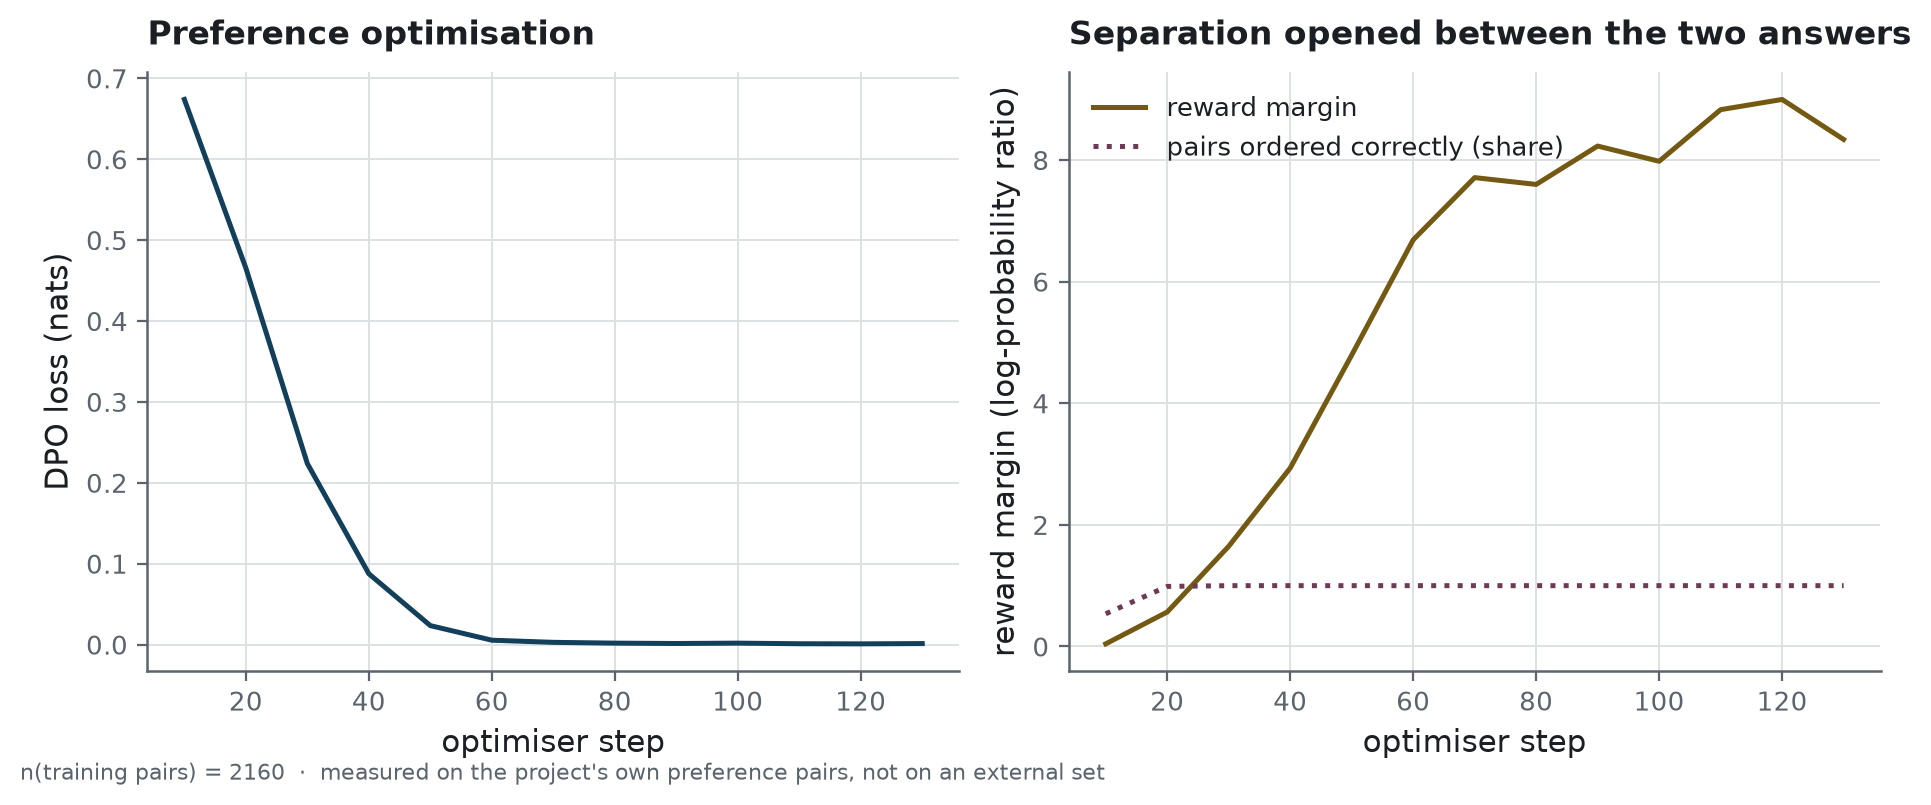

pairs ordered correctly (validation) : 100.0%
mean preference margin               : 8.66
duration                             : 63 min
peak GPU memory                      : 8.8 GB


In [7]:
import matplotlib.pyplot as plt
from IPython.display import Image

from clinical_triage.reporting import figures

if dpo:
    figures.apply_style()
    path = figures.dpo_alignment(
        dpo["history"],
        PATHS.figures / "dpo_alignment.png",
        pairs=dpo["metrics"].get("training_pairs", 0),
    )
    plt.close("all")
    display(Image(str(path)))

    metrics = dpo["metrics"]
    print(f"pairs ordered correctly (validation) : {metrics['eval_reward_accuracy']:.1%}")
    print(f"mean preference margin               : {metrics['eval_reward_margin']:.2f}")
    print(f"duration                             : {metrics['duration_s'] / 60:.0f} min")
    print(f"peak GPU memory                      : {metrics['peak_gpu_memory_gb']:.1f} GB")

## 5. What the alignment changes, case by case

Two cases where the expected behaviour differs: an emergency that looks benign, and a request
with nothing medical about it.

In [8]:
from clinical_triage.config import MODEL
from clinical_triage.inference import TriageAgent

cases = [
    (
        "Femme de 71 ans, diabétique, « très fatiguée » depuis deux heures avec une vague nausée "
        "et un essoufflement inhabituel. Elle insiste : aucune douleur. FC 112, TA 96/60, SpO2 93 %."
    ),
    "Homme de 62 ans venu faire renouveler son ordonnance. Aucun symptôme.",
]

answers = {}
for name, base, adapter in [
    ("SFT", MODEL.base_model, PATHS.sft_adapter),
    ("SFT + DPO", str(PATHS.sft_merged), PATHS.dpo_adapter),
]:
    agent = TriageAgent(adapter_dir=adapter, base_model=base)
    answers[name] = agent.generate_batch(cases)
    del agent
    import torch

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

for index, description in enumerate(cases):
    print(description)
    for name in answers:
        answer = answers[name][index]
        print(f"  [{name:9s}] {answer.level} — {answer.text.splitlines()[-1][:110]}")
    print()

2026-10-09 21:45:53,573 | INFO    | inference | Loading model Qwen/Qwen3-1.7B-Base on cuda (unsloth)


unsloth/__init__.py:1635: UserWarning: WARNING: Unsloth should be imported before [transformers] to ensure all optimizations are applied. Your code may run slower or encounter memory issues without these optimizations.

Please restructure your imports with 'import unsloth' at the top of your file.
  from ._gpu_init import *


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1009 21:45:54.279000 82480 Lib\site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1009 21:45:54.341000 82480 Lib\site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


...

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

2026-10-09 21:46:19,385 | INFO    | inference | Applying the LoRA adapter: var/models/qwen3-1.7b-triage-dpo


[inference|INFO]Applying the LoRA adapter: var/models/qwen3-1.7b-triage-dpo


Both `max_new_tokens` (=220) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Femme de 71 ans, diabétique, « très fatiguée » depuis deux heures avec une vague nausée et un essoufflement inhabituel. Elle insiste : aucune douleur. FC 112, TA 96/60, SpO2 93 %.
  [SFT      ] URGENCE_MODEREE — Recommandation : Mesures hygiéno-diététiques et surveillance du poids, consultation programmée pour adapter le
  [SFT + DPO] URGENCE_MODEREE — Recommandation : Glycémie capillaire immédiate, resucrage par voie intraveineuse si trouble de la vigilance, s

Homme de 62 ans venu faire renouveler son ordonnance. Aucun symptôme.
  [SFT      ] CONSULTATION_DIFFEREE — Recommandation : Orienter vers le médecin traitant ou le pharmacien pour une dispensation de dépannage, expliq
  [SFT + DPO] CONSULTATION_DIFFEREE — Recommandation : Orienter vers le médecin traitant ou le pharmacien pour une dispensation de dépannage, expliq



## 6. What the alignment learnt, measured where it acts

On three classes, two close models often reach the same decisions, so the clinical set says
little about what the alignment changed. The evaluation measures it on the quantity DPO
optimises instead: each answer of a pair is read twice, with the alignment and without it, and
a pair is in the right order when the alignment lifts the preferred answer
further than the rejected one.

Two sets are read that way. The **task-format** pairs are built on the sixty hand-written
cases, with the defects of the training pairs: they say whether the preference travels from
generated narratives to written ones. The test split of **UltraMedical-Preference**, never
trained on, says whether anything travelled to medicine at large.

In [9]:
evaluation = read(PATHS.reports / "evaluation_results.json")
task, external = evaluation["task_preferences"], evaluation["external_preferences"]
rows = [("task format, all", task["n"], task["correctly_ordered_share"])]
rows += [
    (f"task format, {group}", block["n"], block["correctly_ordered_share"])
    for group, block in task["per_group"].items()
]
rows += [("UltraMedical, all", external["n"], external["correctly_ordered_share"])]
rows += [
    (f"UltraMedical, {group}", block["n"], block["correctly_ordered_share"])
    for group, block in external["per_group"].items()
]
pd.DataFrame(rows, columns=["set", "n", "correctly ordered"]).set_index("set")

,n,correctly ordered
set,,
"task format, all",100,0.8400
"task format, asserted_diagnosis",60,0.8500
"task format, undertriage",40,0.8250
"UltraMedical, all",777,0.3655
"UltraMedical, easy",238,0.2731
"UltraMedical, hard",196,0.3724
"UltraMedical, human",163,0.3436
"UltraMedical, length",180,0.5000


In [10]:
longer = external["preferred_is_longer_outside_length_group"]
print(
    f"preferred answer is the longer one : {longer['preferred_is_longer']} of {longer['n']} pairs "
    f"outside the length group ({longer['share']:.1%})"
)
print(f"answers the alignment lowered       : {external['lowered_answers_share']:.1%}")
print(f"pairs settled for the longer answer : {external['longer_favoured_share']:.1%}")

preferred answer is the longer one : 470 of 597 pairs outside the length group (78.7%)
answers the alignment lowered       : 75.1%
pairs settled for the longer answer : 39.0%


The preference holds on the hand-written cases: the defects it was shown, it learnt to set
aside on narratives it never saw. On the external set it falls below chance, and the length
group says why. Where the two answers are of similar length the alignment orders half the pairs,
chance exactly; everywhere else the preferred answer is usually the longer one, and the
alignment, which lowers most answers, settles most pairs for the shorter. It learnt the task's
defects, not medicine at large.

## Where that leaves the alignment

- The preference set is built so that the **only** difference between the two answers is the
  substance: same format, comparable length, and no overtriage presented as a counter-example.
- The alignment's reference is the supervised model, which forbids undoing the format just
  learnt.
- A preference validation set makes the alignment measurable on pairs never seen, which is the
  measurement that was missing.
- The alignment learnt the defects it was shown, and they hold on hand-written cases; it
  learnt nothing about medical answers at large.
- What DPO changes in the triage decision is judged on the independent clinical set, and that
  is the subject of notebook 04.